# SEM basics · 1 — the mesh and the time step

`PropSEM` builds its spectral-element mesh from the same `shape` and `dh` as an
FD grid, but the mesh is made of **elements**, each `n_order` grid cells wide,
with `n_order + 1` Gauss-Lobatto-Legendre (GLL) nodes along each side. This
notebook shows what that means in practice:

1. **The two tiling rules** — which `shape` and `abcn` are allowed
2. **Choosing `dh` and `dt`** — `suggest_discretization` from the velocities and the frequency
3. **Looking at the mesh** — elements, GLL nodes, the absorbing layer, `solver.mesh`
4. **A free surface with topography** — the mesh follows the surface
5. **Internal interfaces** — the mesh follows them too, and the model steps exactly there
6. **Why `dt` matters** — the stable step is set by the GLL spacing, not by `dh`

Runs in about a minute on a GPU (a few on the CPU).

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM, suggest_discretization, gll_nodes_weights
from sweep.sem.equations import AcousticPotentialSEM2D, AcousticSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. The tiling rules

An element covers `n_order x n_order` grid cells, and the grid is tiled by whole
elements. So every axis of `shape` must satisfy `(n - 1) % n_order == 0`, and the
absorbing layer `abcn` (in grid cells, added outside the model as on `PropTorch`)
must be a whole number of elements. `PropSEM` checks both and says what to use
instead:

In [2]:
def try_build(**kw):
    args = dict(shape=(65, 129), dh=10.0, dt=1e-3, n_order=4, abcn=16,
                device=device)
    args.update(kw)
    try:
        PropSEM(AcousticPotentialSEM2D, **args)
        print(kw, '-> ok')
    except ValueError as err:
        print(kw, '->', err)

try_build()                     # 64 = 16 x 4 cells across, 128 = 32 x 4: fine
try_build(shape=(64, 129))      # 63 cells is not a whole number of elements
try_build(abcn=10)              # nor is a 10-cell absorbing layer
try_build(n_order=8)            # order 8 needs multiples of 8 cells: 64 and 128 are

{} -> ok
{'shape': (64, 129)} -> every (n-1) in shape (64, 129) must be divisible by n_order = 4 to tile the grid exactly.
{'abcn': 10} -> abcn=10 is not a whole number of elements: the absorbing layer is made of elements of n_order=4 cells, so abcn must be a multiple of 4 (e.g. 12).
{'n_order': 8} -> ok


## 2. Choosing `dh` and `dt`

Two numbers decide whether a SEM run is accurate and stable:

- **points per wavelength** — about 5 GLL points per shortest wavelength at
  `n_order=4`. The wavelength is `v_min / f_max` with `f_max ≈ 2.5 f0` for a
  Ricker; use `vs` as `v_min` on the elastic equations.
- **the time step** — set by the *closest* pair of GLL nodes and the fastest
  velocity `v_max`.

`suggest_discretization` does both for a domain of a given size. It returns the
number of elements and a time step:

In [3]:
x_max, z_max = 1280.0, 640.0          # domain (m)
v_min, v_max, f0 = 1500.0, 3000.0, 10.0

d = suggest_discretization(x_max, z_max, v_min=v_min, v_max=v_max, f0=f0,
                           n_order=4, record_length=1.0)
print(d)

SEMDiscretization(n_order=4, nex=27, nez=14, dt=7.80e-04, nt=1283  |  λ_min=60.0 m, h_e≈47×46 m, 5.1 pts/λ)


It asks for elements no larger than about 47 m and `dt <= 0.78 ms`. Elements of
40 m are a round choice: `dh = 10 m` with `n_order = 4`, so the model is
`(65, 129)` grid points, 16 x 32 elements. We keep a slightly smaller step than
suggested.

In [4]:
n_order = 4
dh = 10.0
shape = (int(z_max / dh) + 1, int(x_max / dh) + 1)
dt = 0.75e-3
nt = int(round(1.0 / dt))
print('shape', shape, ' elements', (shape[0] - 1) // n_order, 'x', (shape[1] - 1) // n_order,
      ' dt', dt, ' nt', nt)

shape (65, 129)  elements 16 x 32  dt 0.00075  nt 1333


Why is the step so much smaller than an FD step on a 10 m grid? Inside an
element the GLL nodes are not evenly spaced: they cluster at the element edges.
At order 4 the closest pair is only `0.17 x` the element size apart, about 7 m
here, and the CFL condition sees that spacing:

GLL nodes in one 40 m element (m): [ 0.    6.91 20.   33.09 40.  ]
closest spacing: 6.91 m  (grid spacing 10 m)


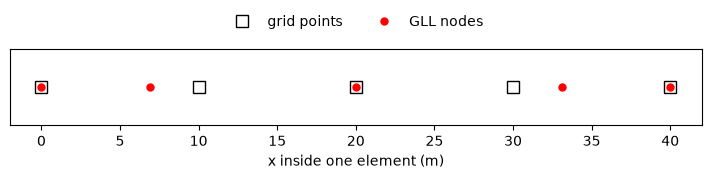

In [5]:
xi, w = gll_nodes_weights(n_order)            # on the reference element [-1, 1]
h_e = n_order * dh
nodes = (xi.numpy() + 1) / 2 * h_e            # in metres inside one element
print('GLL nodes in one 40 m element (m):', np.round(nodes, 2))
print('closest spacing: %.2f m  (grid spacing %.0f m)' % (np.diff(nodes).min(), dh))

fig, ax = plt.subplots(figsize=(7, 1.4), constrained_layout=True)
ax.plot(np.arange(n_order + 1) * dh, np.zeros(n_order + 1), 'ks', ms=8,
        mfc='none', label='grid points')
ax.plot(nodes, np.zeros_like(nodes), 'ro', ms=5, label='GLL nodes')
ax.set_yticks([]); ax.set_xlabel('x inside one element (m)')
ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.6), frameon=False)
plt.show()

The grid points are only where you give the model and place sources and
receivers. `PropSEM` interpolates the model onto the GLL nodes, and the
gradient comes back on the grid.

## 3. Looking at the mesh

`solver.mesh` is the mesh `PropSEM` built: the model **and** its absorbing
layer. With a free surface on top, the C-PML is added on the other three sides
only. Each element is stored by its 3 x 3 control nodes (`control_xy`), and
`x_global` / `z_global` hold the GLL nodes, each shared node once.

In [6]:
solver = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt,
                 n_order=n_order, abcn=16, free_surface=True,
                 f_dominant=f0, device=device)
mesh = solver.mesh
print(type(mesh).__name__, '|', mesh.nez, 'x', mesh.nex, 'elements |',
      mesh.n_global, 'GLL nodes | box %.0f x %.0f m' % (mesh.z_max, mesh.x_max))
print('absorbing layer:', solver.abcn, 'cells =', solver.abcn_elements,
      'elements on', [s for s in ('left', 'right', 'bottom')])

Quad9Mesh | 20 x 40 elements | 13041 GLL nodes | box 800 x 1600 m
absorbing layer: 16 cells = 4 elements on ['left', 'right', 'bottom']


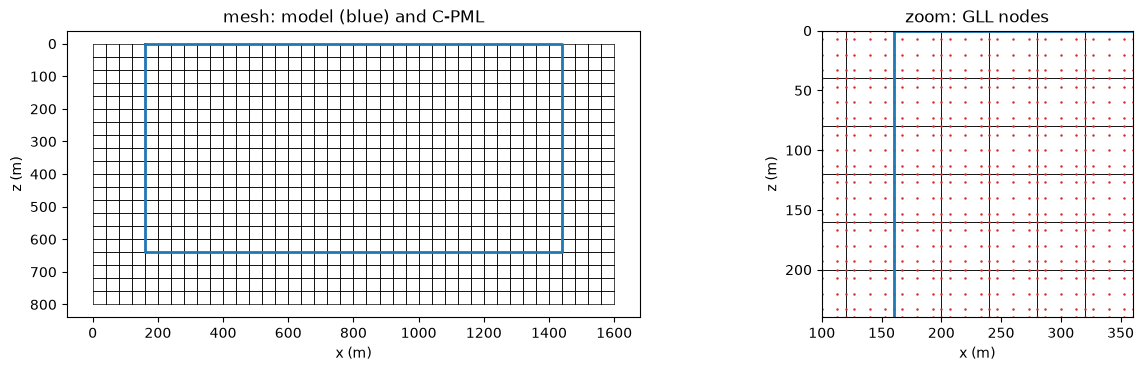

In [7]:
def plot_mesh(ax, mesh, model_box=None, nodes=True):
    """Element edges (through the 3 control nodes of each side) and GLL nodes."""
    cxy = mesh.control_xy.cpu().numpy()                 # (E, 3, 3, 2): [.., (x, z)]
    for e in range(cxy.shape[0]):
        c = cxy[e]
        for side in (c[0, :], c[-1, :], c[:, 0], c[:, -1]):
            ax.plot(side[:, 0], side[:, 1], 'k-', lw=0.5)
    if nodes:
        ax.plot(mesh.x_global.cpu(), mesh.z_global.cpu(), '.', color='tab:red', ms=1.5)
    if model_box is not None:
        x0, x1, z0, z1 = model_box
        ax.plot([x0, x1, x1, x0, x0], [z0, z0, z1, z1, z0], color='tab:blue', lw=2)
    ax.set_aspect('equal'); ax.invert_yaxis()
    ax.set_xlabel('x (m)'); ax.set_ylabel('z (m)')

pad = solver.abcn * dh                                 # C-PML width in metres
box = (pad, pad + x_max, 0.0, z_max)                   # the model inside the mesh

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[2.2, 1]))
plot_mesh(axes[0], mesh, box, nodes=False)
axes[0].set_title('mesh: model (blue) and C-PML')
plot_mesh(axes[1], mesh, box)
axes[1].set_xlim(pad - 60, pad + 200); axes[1].set_ylim(240, 0)
axes[1].set_title('zoom: GLL nodes')
plt.show()

The mesh coordinates start at the outer edge of the absorbing layer, but you
never use them directly: sources and receivers are given as **grid indices**
`[ix, iz]` of the model, exactly as on `PropTorch`, and `PropSEM` converts them.

## 4. A free surface with topography

`topography` gives the surface row of every column (fractional rows allowed;
larger = deeper). It needs an equation on a deformable Quad9 mesh — the
equations whose name ends in `Deformed`, plus `AcousticPotentialSEM2D` and the
fluid–solid `AcousticElasticSEM2D` (see the equation table in the next notebook).
The element columns stretch vertically so that the top row of elements follows
the surface exactly; there is no staircase.

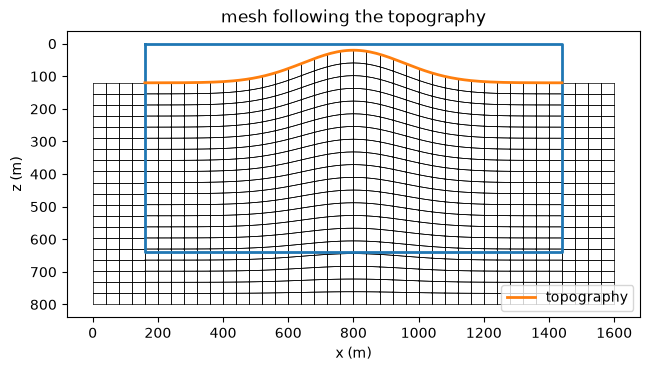

In [8]:
ix = np.arange(shape[1])
topo = 12.0 - 10.0 * np.exp(-((ix - 64) / 22.0) ** 2)   # a 100 m hill, row 12 -> row 2
solver_topo = PropSEM(AcousticSEM2DDeformed, shape=shape, dh=dh, dt=dt,
                      n_order=n_order, abcn=16, topography=topo,
                      f_dominant=f0, device=device)

fig, ax = plt.subplots(figsize=(12, 3.6), constrained_layout=True)
plot_mesh(ax, solver_topo.mesh, box, nodes=False)
ax.plot(pad + ix * dh, topo * dh, color='tab:orange', lw=2, label='topography')
ax.legend(loc='lower right'); ax.set_title('mesh following the topography')
plt.show()

Above the surface there is no mesh: grid points in the air are not part of the
model, and a model value there is never read.

## 5. Internal interfaces

A model on the grid is interpolated onto the GLL nodes, bilinearly, so a step
in it becomes a ramp one grid cell wide, and an element that the step crosses
holds it as one smooth polynomial. With `interfaces=` the mesh follows internal
interfaces as it follows the topography:

- each interface is given like `topography`: its row in every column,
  fractional rows allowed, top-down;
- the surface, the interfaces and the model's last row bound the layers, and each
  layer gets whole element rows, graded in every column between its two
  interfaces. `interface_elements` sets the number of rows per layer; by default
  the layers share them by their mean thickness;
- the absorbing pads join the layers next to them.

This is 2-D only, on the Quad9 equations. The hill of section 4 over a
dome-shaped interface, 360 m deep at the sides and 260 m under the crest:

element rows per layer: [7, 13] (the lower one includes the 4 rows of the C-PML)


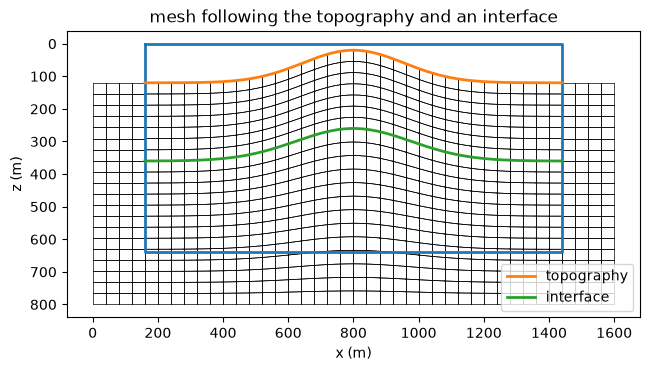

In [9]:
interface = 36.0 - 10.0 * np.exp(-((ix - 64) / 25.0) ** 2)    # rows, top-down
solver_l = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=16, topography=topo, interfaces=[interface], f_dominant=f0,
                   device=device)
layer = solver_l.element_layer                 # (n_elements,): 0 above the interface, 1 below
rows = layer.view(solver_l.mesh.nez, solver_l.mesh.nex)[:, 0]
print('element rows per layer:', [int((rows == k).sum()) for k in range(2)],
      '(the lower one includes the 4 rows of the C-PML)')

fig, ax = plt.subplots(figsize=(12, 3.6), constrained_layout=True)
plot_mesh(ax, solver_l.mesh, box, nodes=False)
ax.plot(pad + ix * dh, topo * dh, color='tab:orange', lw=2, label='topography')
ax.plot(pad + ix * dh, interface * dh, color='tab:green', lw=2, label='interface')
ax.legend(loc='lower right'); ax.set_title('mesh following the topography and an interface')
plt.show()

`solver.layered_model(values)` gives a model on the GLL nodes, of shape
`(n_elements, ngll, ngll)`, with one value per layer (top-down). It steps exactly
at the interface: the nodes on an element edge belong to the elements on both
sides, and each element keeps its own value there. `PropSEM` takes a model of
that shape as it is. The two models along the vertical line through the crest,
as the solver sees them:

layered model: (800, 5, 5)


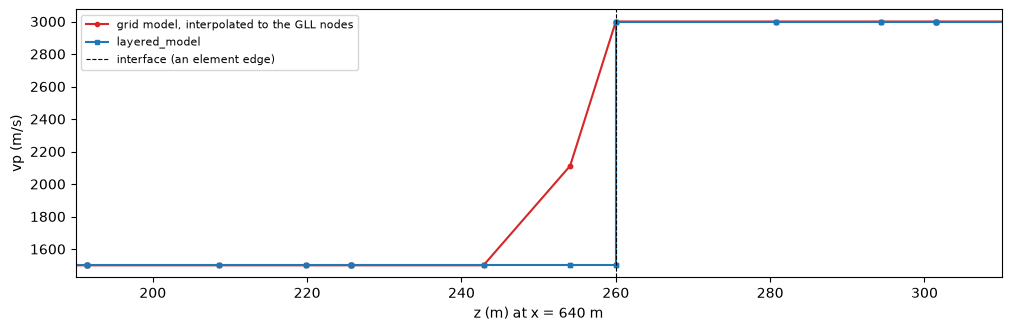

In [10]:
from scipy.interpolate import RegularGridInterpolator

vp_layers = solver_l.layered_model([1500.0, 3000.0])          # (n_elements, 5, 5)
print('layered model:', tuple(vp_layers.shape))

vp_grid = np.where(np.arange(shape[0])[:, None] < interface[None, :], 1500.0, 3000.0)
on_grid = RegularGridInterpolator((np.arange(shape[0]) * dh, ix * dh), vp_grid)

xe = solver_l.mesh.x_e.cpu().numpy() - pad                    # model coordinates (m)
ze = solver_l.mesh.z_e.cpu().numpy()
line = (np.abs(xe - 64 * dh) < 1e-6) & (ze <= z_max)          # the GLL nodes at x = 640 m, above the C-PML
order = np.argsort(ze[line], kind='stable')                   # by depth, element by element
z_line = ze[line][order]
z_i = interface[64] * dh
fig, ax = plt.subplots(figsize=(10, 3.2), constrained_layout=True)
ax.plot(z_line, on_grid(np.stack([z_line, np.full_like(z_line, 64 * dh)], axis=1)), 'o-',
        ms=3, color='tab:red', label='grid model, interpolated to the GLL nodes')
ax.plot(z_line, vp_layers.cpu().numpy()[line][order], 's-', ms=3, color='tab:blue',
        label='layered_model')
ax.axvline(z_i, color='k', ls='--', lw=0.8, label='interface (an element edge)')
ax.set_xlim(z_i - 70, z_i + 50)
ax.set_xlabel('z (m) at x = 640 m'); ax.set_ylabel('vp (m/s)'); ax.legend(fontsize=8)
plt.show()

The interpolated grid model climbs from 1500 to 3000 m/s over the grid cell
above the interface, inside the element above it. `layered_model` has 1500 m/s
down to the interface and 3000 m/s below it.

What that does to a record: one shot over the same dome under a flat surface,
with the grid model and with `layered_model`, each on the mesh it needs, against
the layered model on elements a quarter as large (`dh = 2.5`). All runs take
that mesh's time step, so they differ only in space:

relative difference to the fine mesh, 0.3-0.8 s, offsets 40-300 m:
 elements  grid model  layered
     40 m       0.359    0.125
     20 m       0.102    0.043


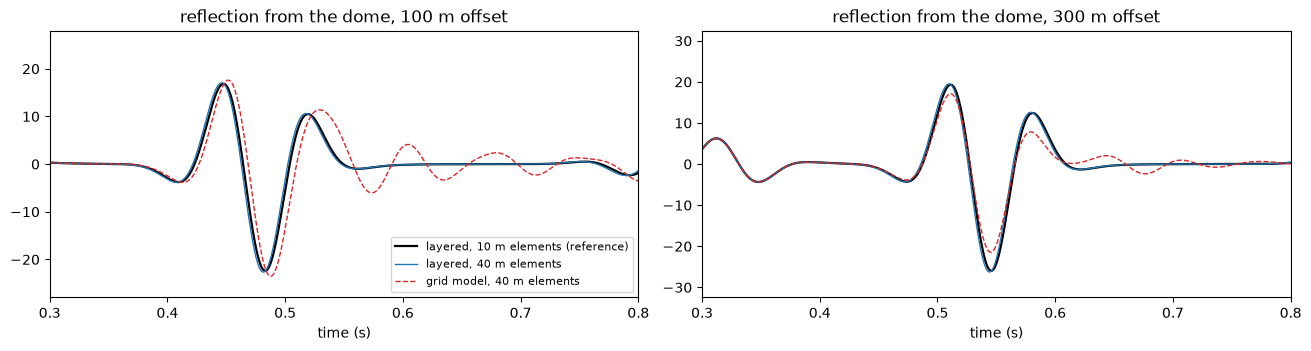

In [11]:
dt_fine = 0.15e-3
nt_fine = int(round(0.9 / dt_fine))
wav_fine = ricker(np.arange(nt_fine) * dt_fine - 0.12, f=f0).astype(np.float32)

def interface_run(dh_k, layered):
    """One shot over the dome on a (dh / dh_k)-times finer grid; the record at the
    receivers every 20 m, 20 m deep."""
    k = int(round(dh / dh_k))
    shape_k = ((shape[0] - 1) * k + 1, (shape[1] - 1) * k + 1)
    x_k = np.arange(shape_k[1]) * dh_k
    z_dome = 360.0 - 100.0 * np.exp(-((x_k - 640.0) / 250.0) ** 2)    # metres
    kw = dict(shape=shape_k, dh=dh_k, dt=dt_fine, n_order=n_order, abcn=16 * k,
              free_surface=True, f_dominant=f0, device=device)
    if layered:
        s = PropSEM(AcousticPotentialSEM2D, interfaces=[z_dome / dh_k], **kw)
        model = s.layered_model([1500.0, 3000.0])
    else:
        s = PropSEM(AcousticPotentialSEM2D, **kw)
        z_k = np.arange(shape_k[0])[:, None] * dh_k
        model = torch.tensor(np.where(z_k < z_dome[None, :], 1500.0, 3000.0),
                             dtype=torch.float32, device=device)
    rx_k = np.arange(0, shape_k[1], 2 * k)
    rec_k = np.stack([rx_k, np.full_like(rx_k, 2 * k)], axis=1)[None]
    with torch.no_grad():
        return s(wav_fine, np.array([[64 * k, 2 * k]]), rec_k, models=[model])[0, :, :, 0].cpu().numpy()

ref = interface_run(2.5, True)
runs = {(d, lay): interface_run(d, lay) for d in (10.0, 5.0) for lay in (False, True)}

t_f = np.arange(nt_fine) * dt_fine
offset = np.abs(np.arange(ref.shape[1]) * 20.0 - 640.0)
window = (t_f > 0.3) & (t_f < 0.8)                            # the reflection
near = (offset >= 40) & (offset <= 300)                       # before the critical angle
def misfit(r):
    return np.linalg.norm((r - ref)[window][:, near]) / np.linalg.norm(ref[window][:, near])
print('relative difference to the fine mesh, 0.3-0.8 s, offsets 40-300 m:')
print(f"{'elements':>9s} {'grid model':>11s} {'layered':>8s}")
for d in (10.0, 5.0):
    print(f'{4 * d:7.0f} m {misfit(runs[d, False]):11.3f} {misfit(runs[d, True]):8.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), constrained_layout=True)
for ax, off in zip(axes, (100, 300)):
    j = 32 + off // 20
    ax.plot(t_f, ref[:, j], 'k', lw=1.6, label='layered, 10 m elements (reference)')
    ax.plot(t_f, runs[10.0, True][:, j], color='tab:blue', lw=1, label='layered, 40 m elements')
    ax.plot(t_f, runs[10.0, False][:, j], '--', color='tab:red', lw=1, label='grid model, 40 m elements')
    ax.set_xlim(0.3, 0.8)
    ax.set_ylim(np.array([-1.25, 1.25]) * np.abs(ref[window, j]).max())
    ax.set_title(f'reflection from the dome, {off} m offset'); ax.set_xlabel('time (s)')
axes[0].legend(fontsize=8, loc='lower right')
plt.show()

On the same mesh the grid model is two to three times further from the
reference than `layered_model`, and it rings after the reflection, where the
layered model does not. The layered model's remaining difference is the error
of the elements themselves: it falls with the element size.

## 6. Why `dt` matters

Run the same shot with the chosen step and with steps 1.8x and 2x larger. The
explicit time stepping is stable only below a limit set by the closest GLL
spacing and `v_max`; here the limit lies between the two, so the first run is
fine and the second grows without bound within a few hundred steps. The step
`suggest_discretization` gives keeps a margin below that limit (its `courant=0.3`),
which leaves room for deformed elements under a topography.

In [12]:
vp = torch.full(shape, 1500.0, device=device)
vp[shape[0] // 2:] = 3000.0
src = np.array([[shape[1] // 2, 2]])
rec = np.array([[[shape[1] // 2 + 20, 2]]])           # one receiver, 200 m offset

traces = {}
for factor in (1.0, 1.8, 2.0):
    dt_k = dt * factor
    nt_k = int(round(1.0 / dt_k))
    wav = ricker(np.arange(nt_k) * dt_k - 0.12, f=f0).astype(np.float32)
    s = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt_k,
                n_order=n_order, abcn=16, free_surface=True, f_dominant=f0,
                device=device)
    with torch.no_grad():
        tr = s(wav, src, rec, models=[vp])[0, :, 0, 0].cpu().numpy()
    traces[factor] = (np.arange(nt_k) * dt_k, tr)
    print(f'dt = {dt_k * 1e3:.2f} ms ({factor:g} x): max |trace| = {np.nanmax(np.abs(tr)):.3e}')

dt = 0.75 ms (1 x): max |trace| = 2.901e+01


dt = 1.35 ms (1.8 x): max |trace| = 2.896e+01


dt = 1.50 ms (2 x): max |trace| = 2.238e+10


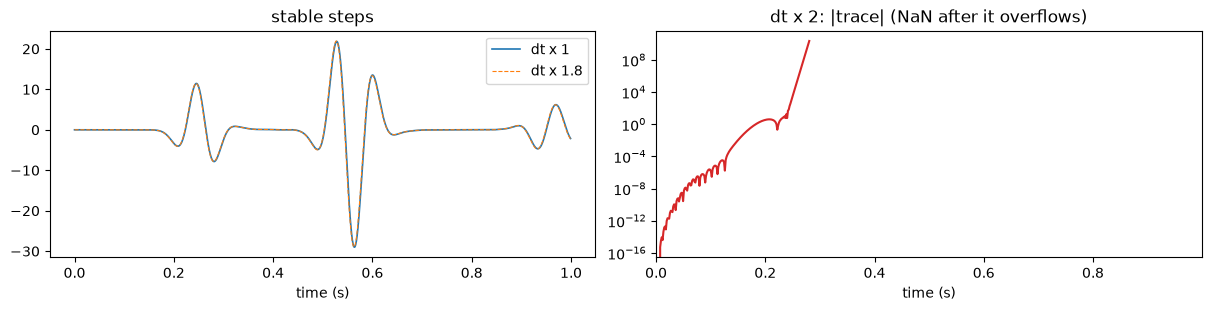

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3), constrained_layout=True)
for factor in (1.0, 1.8):
    t, tr = traces[factor]
    axes[0].plot(t, tr, lw=1.2 if factor == 1 else 0.8,
                 ls='-' if factor == 1 else '--', label=f'dt x {factor:g}')
axes[0].set_xlabel('time (s)'); axes[0].set_title('stable steps'); axes[0].legend()
t, tr = traces[2.0]
with np.errstate(divide='ignore', invalid='ignore'):
    axes[1].semilogy(t, np.abs(tr), color='tab:red')
axes[1].set_xlim(0, t[-1]); axes[1].set_xlabel('time (s)')
axes[1].set_title('dt x 2: |trace| (NaN after it overflows)')
plt.show()

## Summary

| what | rule |
| --- | --- |
| `shape` | every axis `(n - 1) % n_order == 0` |
| `abcn` | a multiple of `n_order` (default: ten elements) |
| resolution | about 5 GLL points per shortest wavelength at `n_order = 4` (`suggest_discretization`) |
| `dt` | from the closest GLL spacing (≈ `0.17 x n_order x dh` at order 4) and `v_max`; `suggest_discretization` gives it with a margin |
| `topography` | surface row per column, on the Quad9 (deformable) equations |
| `interfaces` | rows of internal interfaces per column, top-down (2-D Quad9); `layered_model(values)` gives a model that steps exactly at them |

Next: [SEM basics · 2 — choosing an equation](../51_sem_equations_and_models/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="50_sem_mesh_and_time_step.ipynb" download><code>50_sem_mesh_and_time_step.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/50_sem_mesh_and_time_step.ipynb">view on GitHub</a></p>